# T20 phase 2: which SMARTS noise sources are not quiet?

Companion notebook to `README.md`. Regenerates every figure from `data/` (written by `tools/audit/galaxy_phase2_analysis.py`, `injection_model.py`, `galaxy_tic_map.py`); no drive needed.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
REPORT = REPO / "reports" / "2026-10-21_t20-noise-sources-phase2"
FIG, DATA = REPORT / "figures", REPORT / "data"
FIG.mkdir(exist_ok=True)
src = pd.read_csv(DATA / "sources.csv")
summ = json.loads((DATA / "phase2_summary.json").read_text())
dm = pd.read_csv(DATA / "devmedium_vs_source.csv").merge(src[["galaxy", "classification", "periodic", "pipe_P", "P_ref"]], on="galaxy")
CLS = ["quiet", "systematic_common_mode", "contamination_known_variable", "contamination_candidate_crowded",
       "source_specific_unexplained", "misclassified_star"]
COL = dict(zip(CLS, ["0.75", "tab:purple", "tab:red", "tab:orange", "tab:blue", "tab:green"]))
print(json.dumps({k: summ[k] for k in ("classification", "n_periodic", "files_in_periodic_sources",
                                        "devmedium_strict", "devmedium_wrong_rate")}, indent=1))

{
 "classification": {
  "quiet": 1513,
  "contamination_known_variable": 90,
  "contamination_candidate_crowded": 63,
  "source_specific_unexplained": 44,
  "systematic_common_mode": 8,
  "misclassified_star": 1
 },
 "n_periodic": 206,
 "files_in_periodic_sources": 121502,
 "devmedium_strict": {
  "wrong": 51,
  "null_mean": 0.4,
  "null_max": 3
 },
 "devmedium_wrong_rate": {
  "periodic_source": 0.4296875,
  "quiet_source": 0.03784403669724771,
  "n_periodic": 128
 }
}


## 0. TIC map vs blind fingerprint groups (phase 1)

In [2]:
print(json.loads((DATA / "fingerprint_vs_tic.json").read_text()))
mm = pd.read_csv(DATA / "fingerprint_vs_tic_mismatches.csv")
print(mm.kind.value_counts().to_dict())
display(mm[mm.n > 1])

{'n_files': 172099, 'n_assigned': 172083, 'n_groups': 1718, 'n_groups_single_tic': 1694, 'files_in_majority_tic': 0.9983031444128705, 'n_tics': 1719, 'n_tics_split': 23, 'n_sibling_pairs': 94, 'n_sibling_pairs_same_tic': 2, 'sibling_tic_abs_diff_median': 7.5}
{'impure_group': 48, 'split_tic': 46}


,galaxy_id,tic,n,kind
0,0,10000241254,136,impure_group
1,0,10000255394,120,impure_group
2,1,10000480324,145,impure_group
3,1,10000480315,106,impure_group
4,108,10000423352,152,impure_group
6,137,10000422862,151,impure_group
8,158,10000259266,150,impure_group
10,169,10000259356,149,impure_group
12,209,10001389903,147,impure_group
14,255,10000252251,145,impure_group


## 1. Injection model: multiplicative

Check members of the 146 TICs with corrupt orbits. Ratio of the residual's robust rms inside corrupt cadences to that in clean cadences, for f − g (additive model) and f/g − 1 (multiplicative), vs how far the noise light curve is from 1 there.

|g-1| > 1: n=504 (42 TICs)  add 2.57  mul 1.20
|g-1| > 3: n=168 (14 TICs)  add 6.22  mul 1.17
|g-1| > 10: n=36 (3 TICs)  add 47.51  mul 1.48


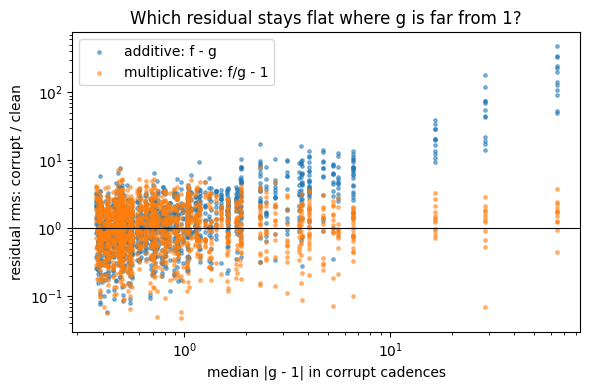

In [3]:
im = pd.read_csv(DATA / "injection_model.csv")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(im.g_abs_dev_median_corrupt, im.add_ratio, s=6, alpha=0.5, label="additive: f - g")
ax.scatter(im.g_abs_dev_median_corrupt, im.mul_ratio, s=6, alpha=0.5, label="multiplicative: f/g - 1")
ax.axhline(1, color="k", lw=0.8)
ax.set(xscale="log", yscale="log", xlabel="median |g - 1| in corrupt cadences",
       ylabel="residual rms: corrupt / clean", title="Which residual stays flat where g is far from 1?")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "injection_model.png", dpi=120)
for lo in (1, 3, 10):
    s = im[im.g_abs_dev_median_corrupt > lo]
    print(f"|g-1| > {lo}: n={len(s)} ({s.galaxy.nunique()} TICs)  add {s.add_ratio.median():.2f}  mul {s.mul_ratio.median():.2f}")

## 2. Do the stacks recover the noise light curve?

Residual (member − A+B median) robust rms vs the member's expected injected amplitude E. Stacking members (A, B; low E) sit far below held-out checks.

       res_rms_ppm  res_p2p_ppm
role                           
A        67.536655     0.249948
B        66.432032     0.249948
check  1723.996286     5.467605


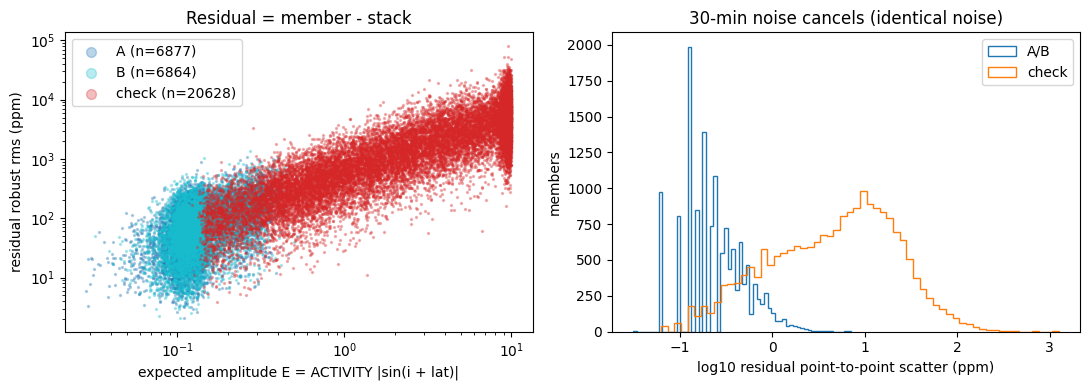

In [4]:
rs = pd.read_csv(DATA / "residuals_sample.csv.gz")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for role, c in (("A", "tab:blue"), ("B", "tab:cyan"), ("check", "tab:red")):
    d = rs[rs.role == role]
    ax[0].scatter(d.E, d.res_rms_ppm, s=2, alpha=0.3, c=c, label=f"{role} (n={len(d)})")
ax[0].set(xscale="log", yscale="log", xlabel="expected amplitude E = ACTIVITY |sin(i + lat)|",
          ylabel="residual robust rms (ppm)", title="Residual = member - stack"); ax[0].legend(markerscale=5)
ax[1].hist(np.log10(rs[rs.role != "check"].res_p2p_ppm.clip(1e-3)), 60, histtype="step", label="A/B")
ax[1].hist(np.log10(rs[rs.role == "check"].res_p2p_ppm.clip(1e-3)), 60, histtype="step", label="check")
ax[1].set(xlabel="log10 residual point-to-point scatter (ppm)", ylabel="members",
          title="30-min noise cancels (identical noise)"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / "stack_validation.png", dpi=120)
print(rs.groupby("role")[["res_rms_ppm", "res_p2p_ppm"]].median())

## 3. Example recovered noise light curves

Two sources per class (two random quiet ones for comparison). Left: the A+B stack over the year. Middle: 6-day zoom with halves A and B overlaid (they agree, so the signal is in the noise source). Right: LS periodogram of A, B and all, with the reference period marked.

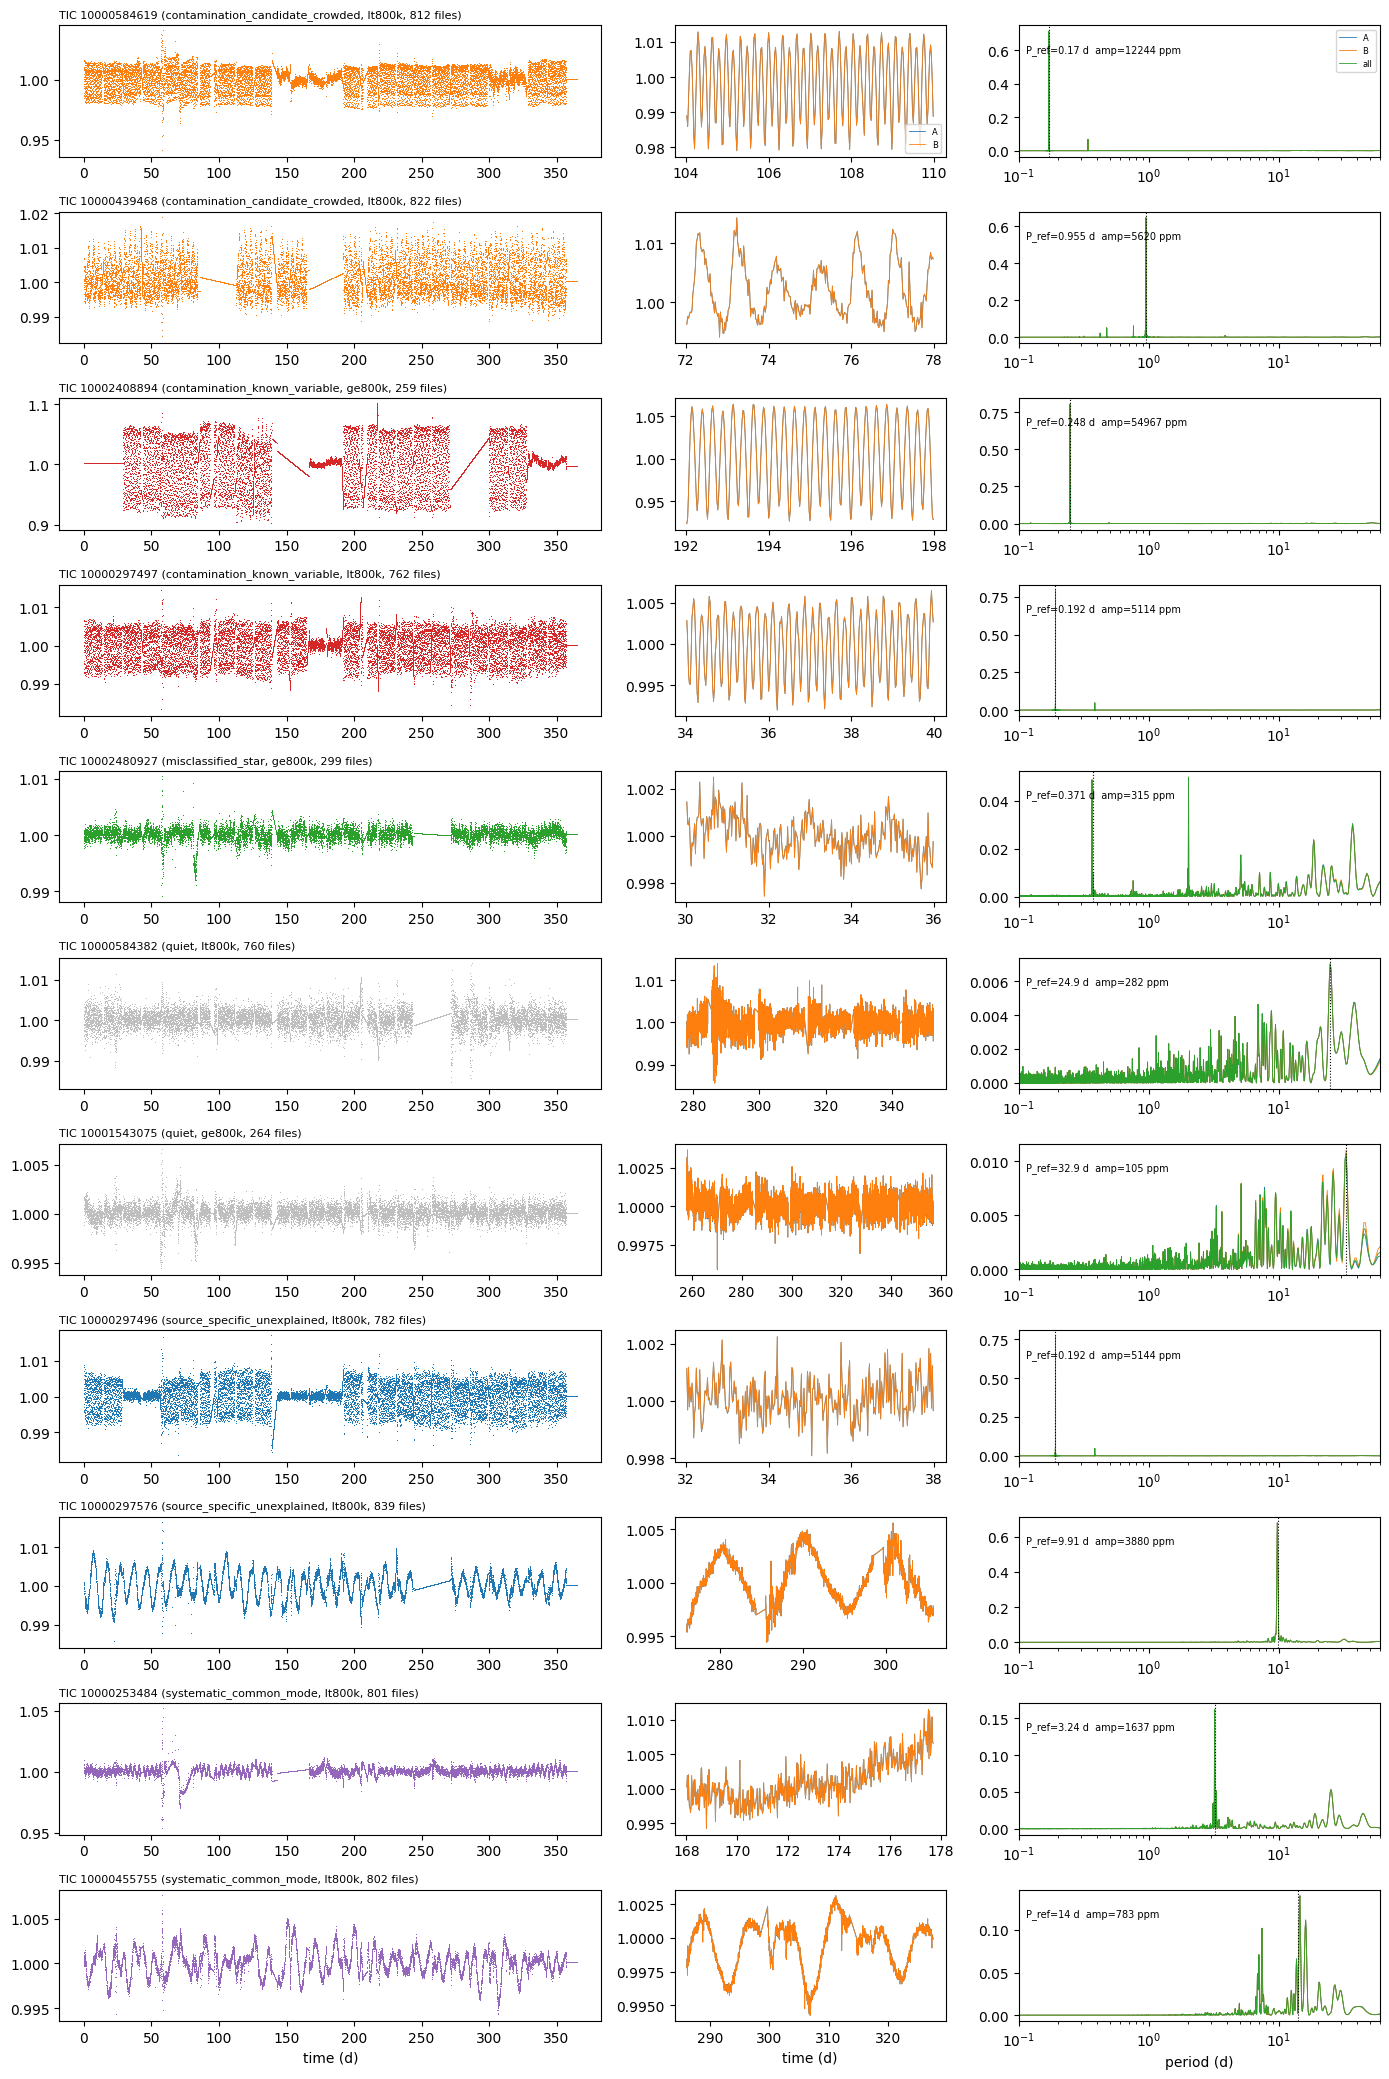

In [5]:
z = np.load(DATA / "example_stacks.npz"); ex = pd.read_csv(DATA / "example_sources.csv")
t = np.arange(z["stacks"].shape[-1]) / 48.0; f = z["ls_freq"]
n = len(ex)
fig, ax = plt.subplots(n, 3, figsize=(14, 1.9 * n), gridspec_kw=dict(width_ratios=[3, 1.5, 2]))
for k, (_, r) in enumerate(ex.iterrows()):
    S = z["stacks"][k]
    ok = np.abs(S[2] - 1) < 0.1
    ax[k, 0].plot(t[ok], S[2][ok], ",", color=COL.get(r.classification, "k"))
    ax[k, 0].set_title(f"TIC {r.tic} ({r.classification}, {r.pool}, {r.n_files} files)", fontsize=8, loc="left")
    P = r.P_ref if np.isfinite(r.P_ref) else 5
    w = max(6, 3 * P)
    real = ok & np.r_[True, np.abs(np.diff(S[2], 2)) > 1e-7, True]   # not linear fill
    t0 = max(np.arange(10, 360 - w, 2), key=lambda a: real[(t > a) & (t < a + w)].sum())
    z_ = (t > t0) & (t < t0 + w) & real
    ax[k, 1].plot(t[z_], S[0][z_], lw=0.6, label="A"); ax[k, 1].plot(t[z_], S[1][z_], lw=0.6, label="B")
    for j, lab in enumerate(("A", "B", "all")):
        ax[k, 2].plot(1 / f, z["ls_power"][k, j], lw=0.6, label=lab)
    ax[k, 2].axvline(P, color="k", ls=":", lw=0.8)
    ax[k, 2].set(xscale="log", xlim=(0.1, 60)); ax[k, 2].text(0.02, 0.8, f"P_ref={P:.3g} d  amp={r.amp1_ppm_all:.0f} ppm",
                                                             transform=ax[k, 2].transAxes, fontsize=7)
ax[0, 1].legend(fontsize=6); ax[0, 2].legend(fontsize=6)
ax[-1, 0].set_xlabel("time (d)"); ax[-1, 1].set_xlabel("time (d)"); ax[-1, 2].set_xlabel("period (d)")
fig.tight_layout(); fig.savefig(FIG / "example_sources.png", dpi=110)

## 4. Population: which sources are periodic, and where are they?

n  frac_gaia_var_within_63as  median_gaia_nb
near_lmc periodic                                                 
False    False     1333                      0.086             6.0
         True       144                      0.264             8.0
True     False      180                      0.667            82.5
         True        62                      0.903           120.5

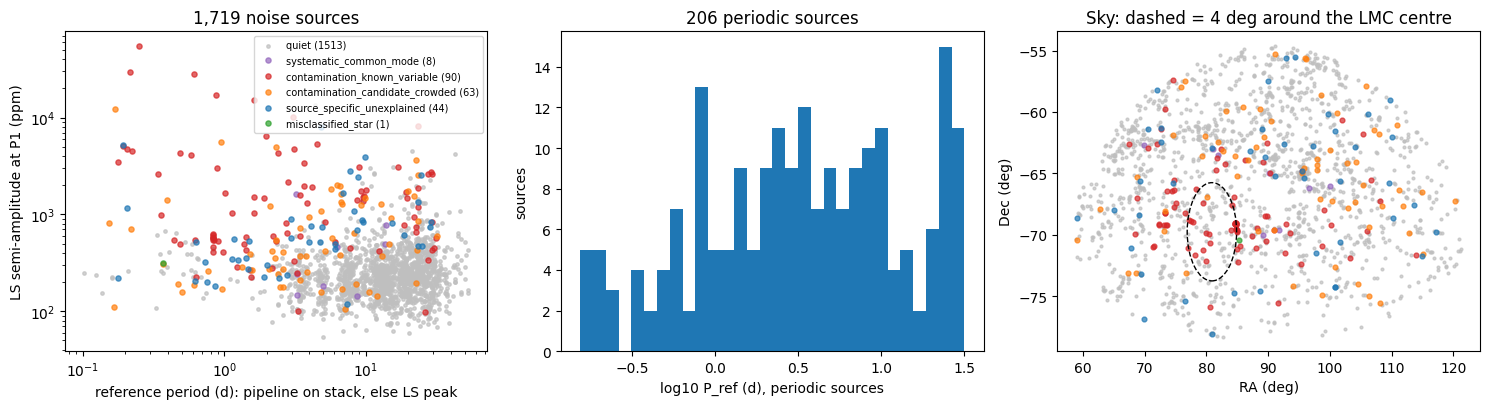

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for c in CLS:
    d = src[src.classification == c]
    ax[0].scatter(d.P_ref, d.amp1_ppm_all, s=6 if c == "quiet" else 14, c=COL[c], label=f"{c} ({len(d)})", alpha=0.7)
    ax[2].scatter(d.ra, d.dec, s=4 if c == "quiet" else 12, c=COL[c], alpha=0.7)
ax[0].set(xscale="log", yscale="log", xlabel="reference period (d): pipeline on stack, else LS peak",
          ylabel="LS semi-amplitude at P1 (ppm)", title="1,719 noise sources"); ax[0].legend(fontsize=7)
pp = src[src.periodic]
ax[1].hist(np.log10(pp.P_ref), 30)
ax[1].set(xlabel="log10 P_ref (d), periodic sources", ylabel="sources", title=f"{len(pp)} periodic sources")
from matplotlib.patches import Circle
ax[2].add_patch(Circle((80.89, -69.76), 4, fill=False, ls="--", color="k"))
ax[2].set(xlabel="RA (deg)", ylabel="Dec (deg)", title="Sky: dashed = 4 deg around the LMC centre")
fig.tight_layout(); fig.savefig(FIG / "population.png", dpi=120)
display(src.groupby(["near_lmc", "periodic"]).agg(n=("tic", "size"), frac_gaia_var_within_63as=("n_nb_var", lambda s: (s > 0).mean()),
                                               median_gaia_nb=("n_nb", "median")).round(3))

## 5. Rae's test: dev_medium answers vs their noise source's own period

Each dev_medium star's pipeline answer vs the period the pipeline finds on its noise source's stack (no injected signal).

wrong answers equal to their source's pipeline period: 51 of 88; shuffled-source null mean 0.4, max 3 (200 shuffles)


final_outcome,correct,diffrot,double,half,none,wrong
classification,,,,,,
contamination_candidate_crowded,4,2,0,1,10,17
contamination_known_variable,10,4,2,3,23,24
misclassified_star,0,0,0,0,2,0
quiet,177,42,1,6,613,33
source_specific_unexplained,7,2,0,1,2,14


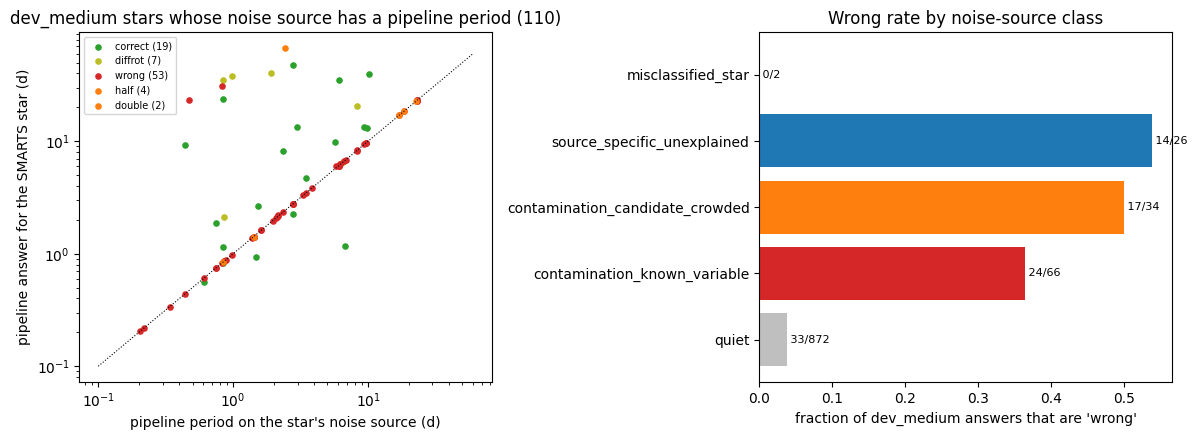

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for o, c in (("correct", "tab:green"), ("diffrot", "tab:olive"), ("wrong", "tab:red"), ("half", "tab:orange"), ("double", "tab:orange")):
    d = dm[(dm.final_outcome == o) & dm.pipe_P.notna()]
    ax[0].scatter(d.pipe_P, d.final_period, s=14, c=c, label=f"{o} ({len(d)})")
x = np.geomspace(0.1, 60, 10); ax[0].plot(x, x, "k:", lw=0.8)
ax[0].set(xscale="log", yscale="log", xlabel="pipeline period on the star's noise source (d)",
          ylabel="pipeline answer for the SMARTS star (d)",
          title=f"dev_medium stars whose noise source has a pipeline period ({dm.pipe_P.notna().sum()})")
ax[0].legend(fontsize=7)
tab = pd.crosstab(dm.classification, dm.final_outcome)
rate = (tab.get("wrong", 0) / tab.sum(1)).reindex(CLS).dropna()
ax[1].barh(rate.index, rate.values, color=[COL[c] for c in rate.index])
for i, c in enumerate(rate.index):
    ax[1].text(rate[c], i, f" {int(tab.loc[c].get('wrong', 0))}/{int(tab.loc[c].sum())}", va="center", fontsize=8)
ax[1].set(xlabel="fraction of dev_medium answers that are 'wrong'", title="Wrong rate by noise-source class")
fig.tight_layout(); fig.savefig(FIG / "devmedium_vs_source.png", dpi=120)
null = summ["devmedium_strict"]
print(f"wrong answers equal to their source's pipeline period: {null['wrong']} of {(dm.final_outcome=='wrong').sum()}; shuffled-source null mean {null['null_mean']}, max {null['null_max']} (200 shuffles)")
display(tab)

## 6. Flag list for Rae (per noise source)

Every non-quiet source with its period, amplitude and evidence. Per-file flags (1M rows) are on the drive: `extracted/galaxy_ids/noise_source_flags.csv.gz`.

In [8]:
cols = ["tic", "galaxy", "pool", "n_files", "classification", "P_ref", "pipe_P", "P1_all", "pow1_all", "amp1_ppm_all",
        "cm_retained", "near_lmc", "n_nb", "n_nb_brighter", "n_nb_var", "nb_var_classes", "cen_PSS", "cen_Gmag", "Tmag", "frac_corrupt"]
flag = src.loc[src.classification != "quiet", cols].sort_values(["classification", "amp1_ppm_all"], ascending=[True, False])
flag.to_csv(DATA / "flagged_noise_sources.csv", index=False)
print(len(flag), "flagged sources,", int(flag.n_files.sum()), "files")
display(flag.head(25))

206 flagged sources, 121502 files


,tic,galaxy,pool,n_files,classification,P_ref,pipe_P,P1_all,pow1_all,amp1_ppm_all,cm_retained,near_lmc,n_nb,n_nb_brighter,n_nb_var,nb_var_classes,cen_PSS,cen_Gmag,Tmag,frac_corrupt
932,10000584619,932,lt800k,812,contamination_candidate_crowded,0.170275,0.170275,0.170571,0.714274,12244.327765,1.025550,False,3.0,1.0,0.0,NaN,0.000000,17.747175,13.090,0.001232
457,10000439468,457,lt800k,822,contamination_candidate_crowded,0.955108,0.955108,0.951224,0.646767,5619.594274,1.008550,False,40.0,1.0,0.0,NaN,NaN,NaN,14.877,0.000000
750,10000457089,750,lt800k,806,contamination_candidate_crowded,2.323993,2.323993,2.294203,0.438141,4982.600798,0.858633,False,7.0,2.0,0.0,NaN,NaN,NaN,14.329,0.000000
1216,10001500437,1216,ge800k,293,contamination_candidate_crowded,22.688125,22.688125,11.099062,0.280294,3610.465911,0.791844,False,7.0,2.0,0.0,NaN,NaN,NaN,14.932,0.000000
1398,10001544655,1398,ge800k,273,contamination_candidate_crowded,23.271876,NaN,23.271876,0.124105,2539.377543,0.713174,False,1.0,1.0,0.0,NaN,NaN,NaN,14.711,1.000000
1488,10001567628,1488,ge800k,278,contamination_candidate_crowded,6.222800,6.222800,6.198215,0.318748,2005.616399,0.997073,False,5.0,1.0,0.0,NaN,NaN,NaN,14.514,0.000000
1290,10001514367,1290,ge800k,270,contamination_candidate_crowded,6.547157,6.547157,6.484543,0.345590,1971.195765,1.015309,False,8.0,2.0,0.0,NaN,NaN,NaN,14.514,0.000000
1111,10001478037,1111,ge800k,250,contamination_candidate_crowded,5.679564,5.679564,5.642431,0.320116,1826.875007,0.959994,False,7.0,1.0,0.0,NaN,NaN,NaN,14.798,0.000000
841,10000480308,841,lt800k,824,contamination_candidate_crowded,19.824993,19.824993,19.328076,0.163007,1723.214109,1.188330,True,46.0,2.0,0.0,NaN,0.997250,18.936000,14.950,0.000000
1268,10001514122,1268,ge800k,295,contamination_candidate_crowded,6.637921,6.637921,6.698779,0.224208,1634.410638,1.087763,False,6.0,1.0,0.0,NaN,NaN,NaN,13.741,0.000000


## 7. Independent FFI light curves (follow-up f)

QLP / TASOC / ELEANOR-LITE light curves (TESS sectors 1-5; no SPOC products exist for these extended TIC IDs), detrended with a running median of 4 P_ref (0.5-5 d). Left: stitched periodogram with the SMARTS stack's period (dotted) and its half/double (faint). Right: folded at P_ref (100-bin medians). Only P_ref < 5 d is testable.

,tic,classification,P_ref,authors,P_top,match,n_sectors_matching,testable,confirmed,smarts_amp_ppm,ffi_amp_at_P_ppm
0,10000297496,source_specific_unexplained,0.192,QLP,0.192,P,3,True,True,5144.029,582.869
1,10000297576,source_specific_unexplained,9.909,GSFC-ELEANOR-LITE,2.052,NaN,1,False,False,3880.436,883.552
2,10000424374,source_specific_unexplained,4.878,TASOC,4.316,NaN,0,True,False,744.681,484.063
3,10000440730,source_specific_unexplained,4.820,TASOC,3.689,P,2,True,True,7938.054,1802.019
4,10001479786,source_specific_unexplained,6.856,TASOC,3.379,P/2,2,False,False,1660.880,1887.862
5,10002408894,contamination_known_variable,0.248,QLP,0.248,P,3,True,True,54967.365,801024.052
6,10000424935,contamination_known_variable,0.217,GSFC-ELEANOR-LITE,0.217,P,3,True,True,29628.992,30294.512
7,10000253005,contamination_known_variable,0.609,GSFC-ELEANOR-LITE,0.203,P,2,True,True,28437.253,990.295
8,10000584619,contamination_candidate_crowded,0.170,QLP,0.171,P,3,True,True,12244.328,335.589
9,10000439468,contamination_candidate_crowded,0.955,TASOC,0.951,P,3,True,True,5619.594,5466.729


testable periodic sources confirmed: 9/12; quiet controls with a match: 4/4


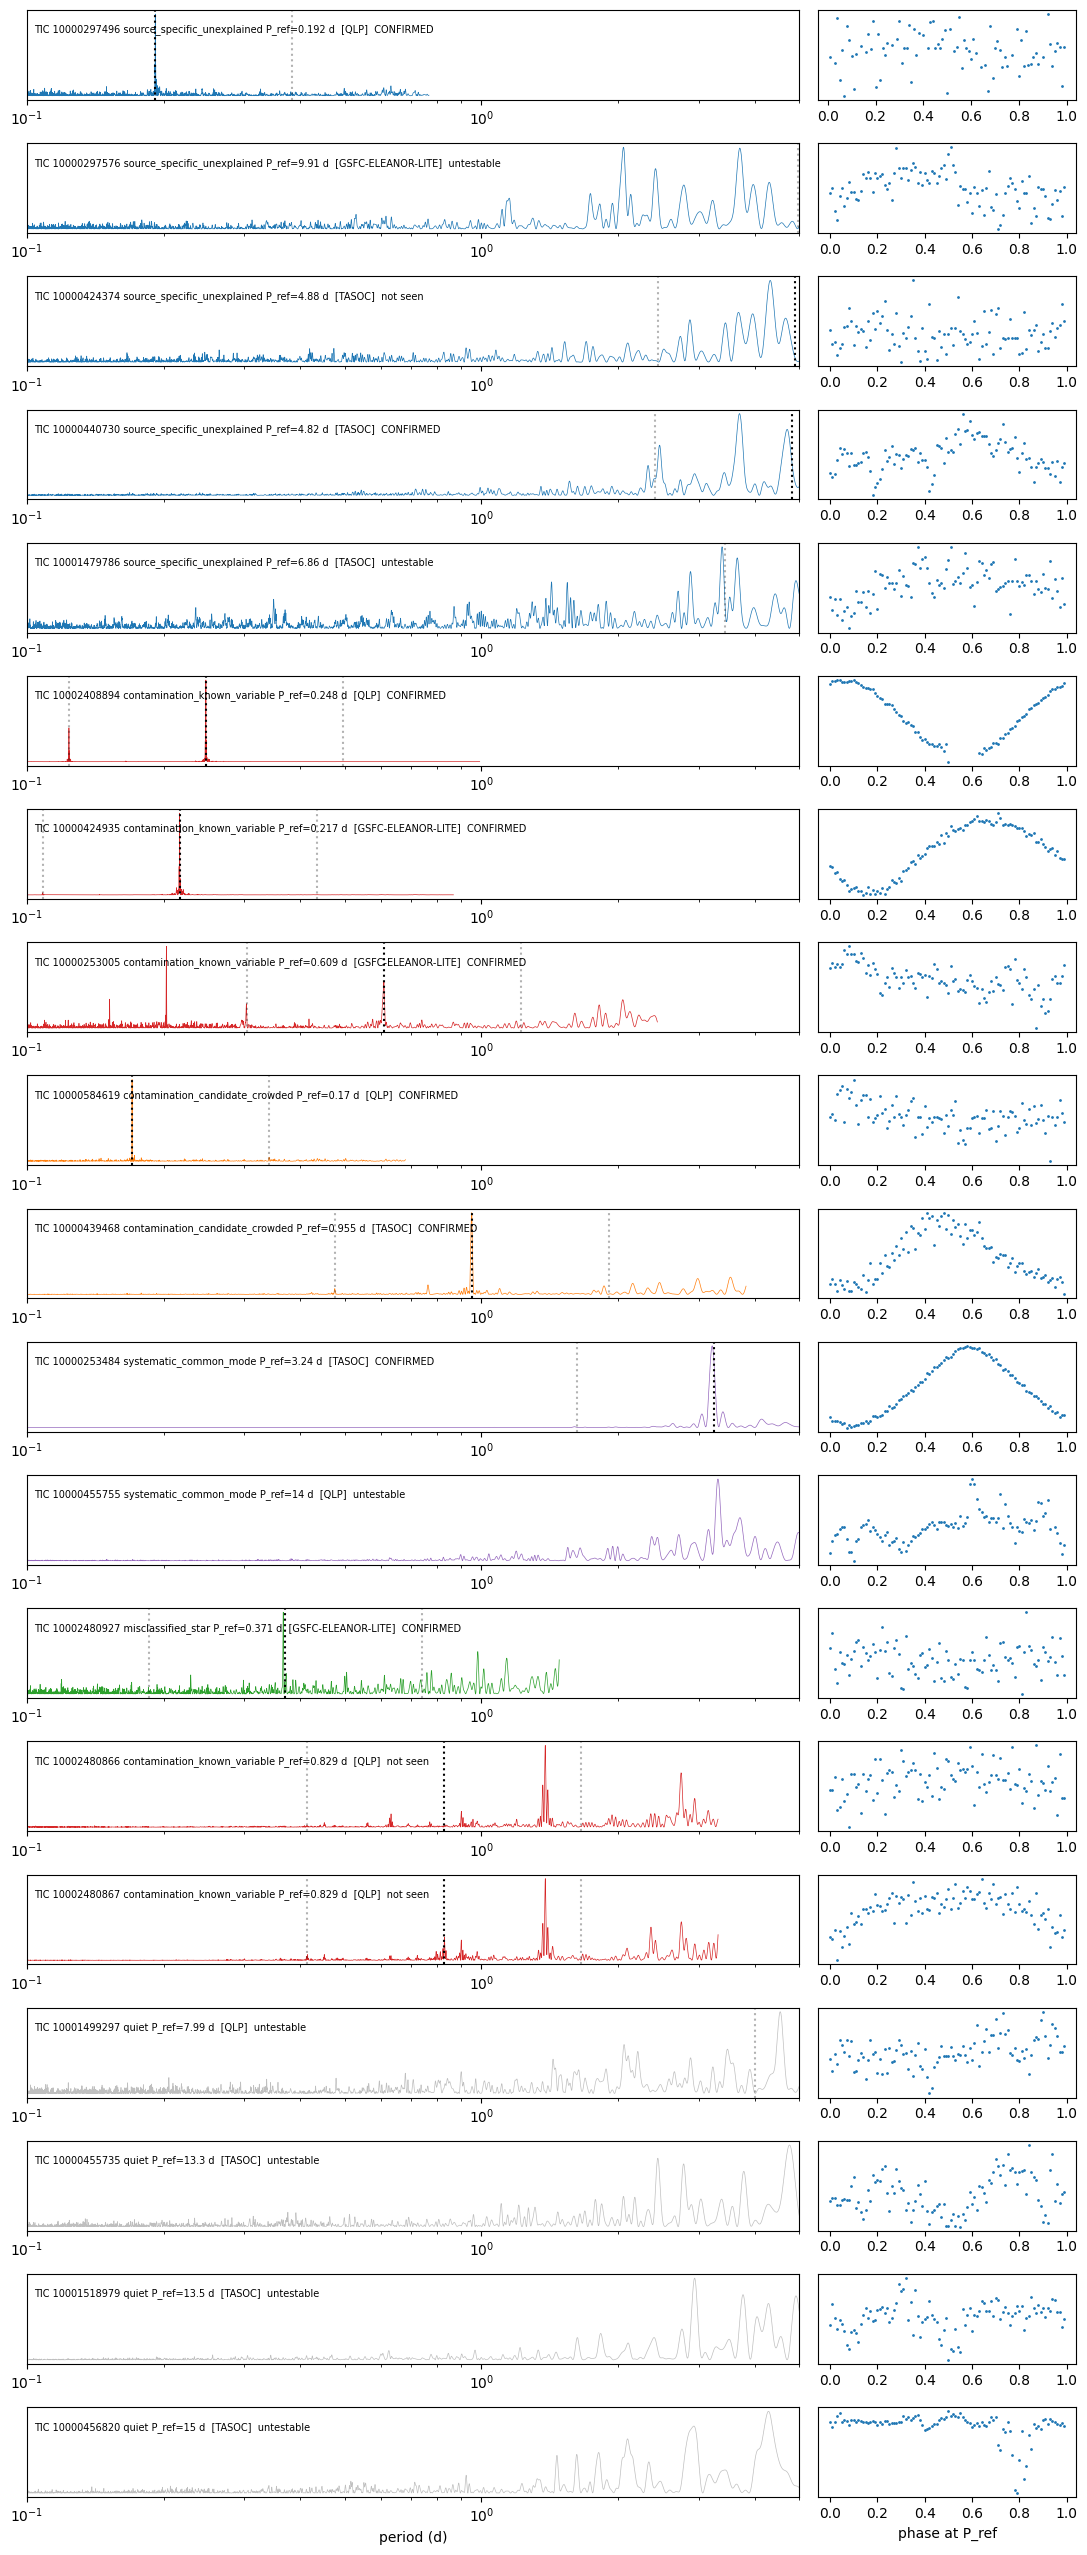

In [9]:
fc = pd.read_csv(DATA / "ffi_compare.csv"); z = np.load(DATA / "ffi_compare_power.npz")
display(fc[["tic", "classification", "P_ref", "authors", "P_top", "match", "n_sectors_matching", "testable", "confirmed",
            "smarts_amp_ppm", "ffi_amp_at_P_ppm"]].round(3))
n = len(fc)
fig, ax = plt.subplots(n, 2, figsize=(11, 1.35 * n), gridspec_kw=dict(width_ratios=[3, 1]))
for k, r in fc.iterrows():
    per = 1 / z["freq"]; m = per <= r.detrend_window_d
    ax[k, 0].plot(per[m], z["power"][k][m], lw=0.5, color=COL.get(r.classification, "k"))
    for q, a in ((r.P_ref, 1), (r.P_ref / 2, 0.3), (2 * r.P_ref, 0.3)):
        ax[k, 0].axvline(q, color="k", ls=":", alpha=a)
    ax[k, 0].set(xscale="log", xlim=(0.1, 5)); ax[k, 0].set_yticks([])
    ax[k, 0].text(0.01, 0.75, f"TIC {r.tic} {r.classification} P_ref={r.P_ref:.3g} d  [{r.authors}]  "
                  + ("CONFIRMED" if r.confirmed else ("untestable" if not r.testable else "not seen")),
                  transform=ax[k, 0].transAxes, fontsize=7)
    ax[k, 1].plot(np.arange(100) / 100, z["phase_profile"][k] * 1e3, ".", ms=2)
    ax[k, 1].set_yticks([])
ax[-1, 0].set_xlabel("period (d)"); ax[-1, 1].set_xlabel("phase at P_ref")
fig.tight_layout(); fig.savefig(FIG / "ffi_check.png", dpi=110)
t = fc[fc.testable & (fc.classification != "quiet")]
print(f"testable periodic sources confirmed: {int(t.confirmed.sum())}/{len(t)}; quiet controls with a match: {int((fc[fc.classification=='quiet'].match != '').sum())}/4")

## 7b. Full independent-FFI check (all 206 periodic sources + 40 quiet controls)

Same method as section 7, run on every periodic source and on 40 quiet controls tested at *shuffled* periods (the chance-match null). Confirmation rate per class among testable sources (P_ref < 5 d), with 95% Wilson intervals; the grey band is the quiet-control null. One-sided Fisher p-values vs that null.

,classification,n_testable,confirmed,rate,ci_lo,ci_hi,p_vs_null,n_untestable
3,quiet,26,4,0.154,0.062,0.335,NaN,14
4,source_specific_unexplained,25,4,0.160,0.064,0.347,0.626,19
0,contamination_candidate_crowded,34,13,0.382,0.239,0.550,0.047,29
1,contamination_known_variable,60,38,0.633,0.507,0.744,0.000,30
5,systematic_common_mode,4,3,0.750,0.301,0.954,0.031,4
2,misclassified_star,1,1,1.000,0.207,1.000,0.185,0


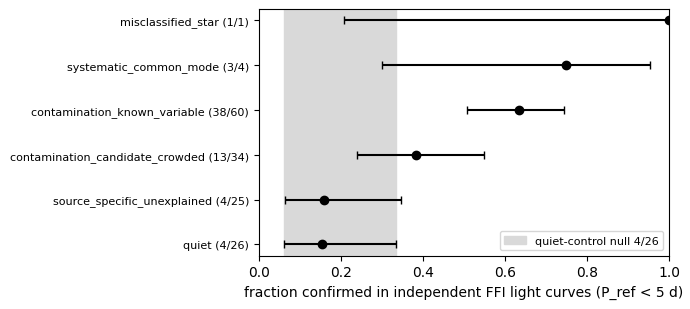

In [10]:
from scipy.stats import binomtest, fisher_exact
fa = pd.read_csv(DATA / "ffi_compare_all.csv")
ta = fa[fa.testable]
qk, qn = int(ta[ta.classification == "quiet"].confirmed.sum()), int((ta.classification == "quiet").sum())
rows = []
for c, g in ta.groupby("classification"):
    k, n = int(g.confirmed.sum()), len(g)
    ci = binomtest(k, n).proportion_ci(method="wilson")
    p = fisher_exact([[k, n - k], [qk, qn - qk]], alternative="greater")[1] if c != "quiet" else np.nan
    rows.append(dict(classification=c, n_testable=n, confirmed=k, rate=k / n, ci_lo=ci.low, ci_hi=ci.high, p_vs_null=p,
                     n_untestable=int(((fa.classification == c) & ~fa.testable).sum())))
summ = pd.DataFrame(rows).sort_values("rate")
display(summ.round(3))
qci = binomtest(qk, qn).proportion_ci(method="wilson")
fig, ax = plt.subplots(figsize=(7, 3.2))
y = np.arange(len(summ))
ax.axvspan(qci.low, qci.high, color="0.85", label=f"quiet-control null {qk}/{qn}")
ax.errorbar(summ.rate, y, xerr=[summ.rate - summ.ci_lo, summ.ci_hi - summ.rate], fmt="o", color="k", capsize=3)
ax.set_yticks(y, [f"{c} ({k}/{n})" for c, k, n in zip(summ.classification, summ.confirmed, summ.n_testable)], fontsize=8)
ax.set(xlabel="fraction confirmed in independent FFI light curves (P_ref < 5 d)", xlim=(0, 1))
ax.legend(fontsize=8, loc="lower right"); fig.tight_layout(); fig.savefig(FIG / "ffi_check_all.png", dpi=120)